**Limitations:** Labels are weak rules, so scores measure agreement with the rule rather than ground truth. Sensing is thermocouple-only. The 0.05 plausibility quantile was chosen after checking held-out results; 0.10 and 0.15 rejected real days. The sensor key is simulated (no hardware). Signing blocks edited data and forged signers, but event hashes are not bound to the signed data, so the oracle's ML verdict is still trusted.

Set dataset paths, fixed labels, feature windows, model parameters, and random seed.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve
from sklearn.model_selection import LeaveOneGroupOut

ROOT = Path("/kaggle/input/datasets/shauryapandey19/phase-2-data")
TRAIN_IDS = ["SUM_7", "SUM_9", "SUM_11", "SUM_17"]
TEST_IDS = ["SUM_18", "SUM_21"]      # held-out households, used only in the final evaluation
LOCAL_TZ = "Africa/Kigali"           # defines where one "usage day" starts and ends
SEED = 42

# Label-rule constants: fixed heuristics, adjust only by looking at TRAIN files
ON_DELTA = 50.0        # degrees C above the idle baseline to count as "hot"
END_FRAC = 0.7         # event ends when temp falls below 70% of its peak (cuts cooldown)
MIN_EVENT_SEC = 600    # events shorter than 10 min are ignored
MERGE_GAP_SEC = 600    # flagged rows less than 10 min apart belong to one event
MIN_PEAK = 250.0       # an event must reach this temperature (C); weak warm bumps are not cooking

WINDOWS = ["10min", "30min", "2h"]
RENAME = {
    "Timestamp": "ts",
    "Thermocouple temperature (C)": "temp",
    "Si7021 temperature (C)": "amb_temp",
    "Si7021 humidity (%RH)": "humidity",
    "Error code": "error",
}
PARAMS = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    class_weight="balanced", random_state=SEED, verbose=-1,
)

Load and clean a household sensor file, preserving local-time indexing.

In [2]:
def load_household(path):
    """Read one SUM file, drop unusable rows, return a frame indexed by local time."""
    df = pd.read_csv(path).rename(columns=str.strip).rename(columns=RENAME)
    for col in ["ts", "temp", "amb_temp", "humidity", "error"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # keep rows with a plausible unix timestamp, no logger error and a valid reading
    keep = df["ts"].between(1e9, 4e9) & (df["error"].fillna(0) == 0) & df["temp"].notna()
    df = df[keep].sort_values("ts").drop_duplicates("ts")

    idx = pd.DatetimeIndex(pd.to_datetime(df["ts"], unit="s", utc=True))
    df.index = idx.tz_convert(LOCAL_TZ).rename("time")
    return df[["ts", "temp", "amb_temp", "humidity"]]

Create weak rule labels and shared event/day utilities.

In [3]:
def label_cooking(df):
    """Rule-based (weak) labels, computed offline using the whole file.
    Used ONLY as the target y, never as a feature.
    A row is cooking if it belongs to a hot run, from the run's start up to the
    last row still above END_FRAC * peak (so the slow cooldown tail is excluded).
    """
    temp, secs = df["temp"].to_numpy(), df["ts"].to_numpy()
    baseline = np.percentile(temp, 5)             # idle stove temperature of this file
    hot = temp > baseline + ON_DELTA
    run_id = np.cumsum(np.r_[True, hot[1:] != hot[:-1]])   # label each run of equal hot/not-hot rows
    labels = np.zeros(len(df), dtype=bool)

    for rid in np.unique(run_id[hot]):
        pos = np.flatnonzero(run_id == rid)
        peak = temp[pos].max()
        last = pos[temp[pos] >= END_FRAC * peak].max()      # last row before the cooldown tail
        pos = pos[pos <= last]
        if secs[pos[-1]] - secs[pos[0]] >= MIN_EVENT_SEC and peak >= MIN_PEAK:
            labels[pos] = True
    return labels.astype(int)


def extract_events(flags, secs):
    """Group flagged rows into (start_sec, end_sec) events.
    Consecutive flagged rows closer than MERGE_GAP_SEC join one event;
    events shorter than MIN_EVENT_SEC are dropped. Used for truth and predictions alike.
    """
    pos = np.flatnonzero(flags)
    if pos.size == 0:
        return []
    events, start, prev = [], pos[0], pos[0]
    for p in pos[1:]:
        if secs[p] - secs[prev] > MERGE_GAP_SEC:       # gap too large: close current event
            events.append((secs[start], secs[prev]))
            start = p
        prev = p
    events.append((secs[start], secs[prev]))
    return [(a, b) for a, b in events if b - a >= MIN_EVENT_SEC]


def usage_days(events):
    """Set of local calendar dates that contain at least one event start."""
    return {pd.Timestamp(a, unit="s", tz="UTC").tz_convert(LOCAL_TZ).date() for a, _ in events}

Build causal sensor features and assemble household datasets.

In [4]:
def build_features(df):
    """Features for each row use only that row and earlier rows (causal).
    Windows are time-based because logging is event-driven (irregular spacing).
    """
    s = df["temp"]
    f = pd.DataFrame(index=df.index)
    f["temp"] = s
    f["temp_minus_amb"] = s - df["amb_temp"]
    f["humidity"] = df["humidity"]
    f["hour"] = df.index.hour

    dt = df["ts"].diff()                               # seconds since previous row
    f["dt_prev"] = dt
    f["slope"] = s.diff() / dt.where(dt > 0)           # degrees C per second

    for w in WINDOWS:
        roll = s.rolling(w)                            # window ends at the current row, looks back only
        f[f"max_{w}"] = roll.max()
        f[f"min_{w}"] = roll.min()
        f[f"mean_{w}"] = roll.mean()
        f[f"std_{w}"] = roll.std()
        f[f"n_rows_{w}"] = roll.count()                # logging density = activity signal
        f[f"drop_from_max_{w}"] = f[f"max_{w}"] - s    # large drop = cooling down

    f["above_24h_min"] = s - s.rolling("24h").min()    # past-only stand-in for an idle baseline
    return f


def build_dataset(ids):
    """Stack features, weak labels, timestamps and household id for several files."""
    frames = []
    for hid in ids:
        df = load_household(ROOT / f"{hid}.csv")
        X = build_features(df)
        X["y"] = label_cooking(df)
        X["ts"] = df["ts"]
        X["household"] = hid
        frames.append(X)
    return pd.concat(frames)

Summarize training labels and cooking-event coverage.

In [5]:
train = build_dataset(TRAIN_IDS)
META = ["y", "ts", "household"]
FEATURES = [c for c in train.columns if c not in META]

rows = []
for hid, g in train.groupby("household"):
    ev = extract_events(g["y"].to_numpy(), g["ts"].to_numpy())
    rows.append({
        "household": hid,
        "rows": len(g),
        "cook_row_%": round(100 * g["y"].mean(), 1),
        "events": len(ev),
        "median_event_min": round(float(np.median([(b - a) / 60 for a, b in ev])), 1) if ev else None,
        "days_with_event": len(usage_days(ev)),
        "days_total": g.index.normalize().nunique(),
    })
print(pd.DataFrame(rows).to_string(index=False))

household  rows  cook_row_%  events  median_event_min  days_with_event  days_total
   SUM_11  1024        17.1       5              34.6                4          16
   SUM_17  5369        61.8      54              80.8               16          16
    SUM_7  2731        61.9      48              41.2               13          16
    SUM_9   687        38.6       8              78.3                3          16


Plot the first three days of each training household for a visual label check.

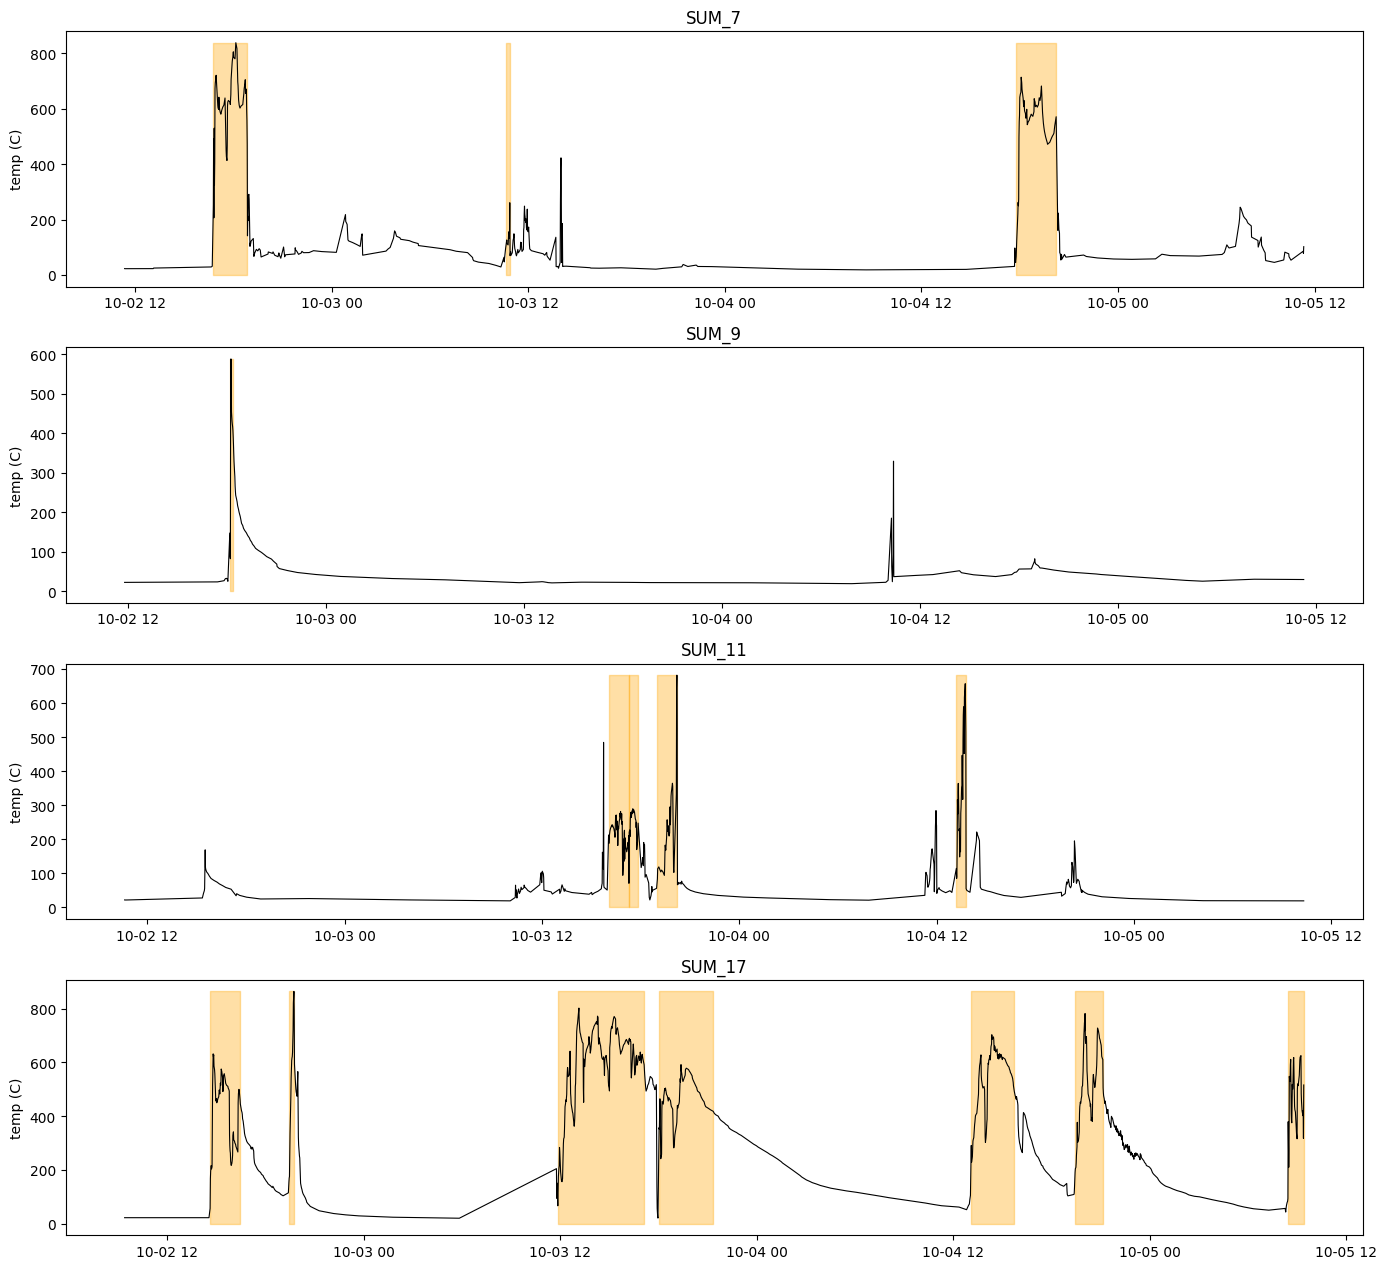

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(TRAIN_IDS), 1, figsize=(14, 3.2 * len(TRAIN_IDS)))
for ax, hid in zip(axes, TRAIN_IDS):
    g = train[train["household"] == hid]
    g = g[g.index < g.index[0] + pd.Timedelta(days=3)]
    ax.plot(g.index, g["temp"], lw=0.8, color="black")
    # shade rows the rule labeled as cooking
    ax.fill_between(g.index, 0, g["temp"].max(), where=g["y"] == 1,
                    color="orange", alpha=0.35, step="post")
    ax.set_title(hid)
    ax.set_ylabel("temp (C)")
plt.tight_layout()
plt.show()

Generate leave-one-household-out predictions and select the F1 threshold.

In [7]:
X_tr, y_tr, groups = train[FEATURES], train["y"], train["household"]

# Out-of-fold (OOF) predictions: each household is predicted by a model that never saw it
oof = np.zeros(len(train))
for fit_idx, val_idx in LeaveOneGroupOut().split(X_tr, y_tr, groups):
    m = LGBMClassifier(**PARAMS).fit(X_tr.iloc[fit_idx], y_tr.iloc[fit_idx])
    oof[val_idx] = m.predict_proba(X_tr.iloc[val_idx])[:, 1]

# Pick the probability threshold that maximises F1 on the OOF predictions
prec, rec, thr = precision_recall_curve(y_tr, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESH = float(thr[f1_curve.argmax()])
OOF_PR_AUC = average_precision_score(y_tr, oof)
print(f"OOF PR-AUC: {OOF_PR_AUC:.3f} | threshold: {THRESH:.3f}")

for hid in TRAIN_IDS:
    mask = (groups == hid).to_numpy()
    print(hid,
          f"PR-AUC {average_precision_score(y_tr[mask], oof[mask]):.3f}",
          f"F1 {f1_score(y_tr[mask], oof[mask] >= THRESH):.3f}")

OOF PR-AUC: 0.934 | threshold: 0.237
SUM_7 PR-AUC 0.950 F1 0.858
SUM_9 PR-AUC 0.944 F1 0.856
SUM_11 PR-AUC 0.765 F1 0.714
SUM_17 PR-AUC 0.945 F1 0.867


Fit the final LightGBM model and evaluate the held-out households.

In [8]:
final_model = LGBMClassifier(**PARAMS).fit(X_tr, y_tr)

test = build_dataset(TEST_IDS)                  # loaded only now, after the model and threshold are fixed
test["prob"] = final_model.predict_proba(test[FEATURES])[:, 1]
test["pred"] = (test["prob"] >= THRESH).astype(int)

for hid, g in test.groupby("household"):
    print(hid,
          f"PR-AUC {average_precision_score(g['y'], g['prob']):.3f}",
          f"F1 {f1_score(g['y'], g['pred']):.3f}")

SUM_18 PR-AUC 0.885 F1 0.878
SUM_21 PR-AUC 0.919 F1 0.844


Compare true and predicted usage days before the export plausibility gate.

In [9]:
verified, report = [], []
for hid, g in test.groupby("household"):
    secs = g["ts"].to_numpy()
    true_day_set = usage_days(extract_events(g["y"].to_numpy(), secs))
    pred_day_set = usage_days(extract_events(g["pred"].to_numpy(), secs))
    hit = len(true_day_set & pred_day_set)

    report.append({
        "household": hid,
        "days_total": g.index.normalize().nunique(),
        "true_days": len(true_day_set),
        "pred_days": len(pred_day_set),
        "day_precision": round(hit / max(len(pred_day_set), 1), 3),
        "day_recall": round(hit / max(len(true_day_set), 1), 3),
    })
    verified += [{"stove_id": hid, "date": d} for d in sorted(pred_day_set)]

print(pd.DataFrame(report).to_string(index=False))
verified_days = pd.DataFrame(verified)     # one row per predicted stove-day before plausibility gating
pre_gate_stove_days = len(verified)
usage_report = pd.DataFrame(report)
true_usage_days = int(usage_report["true_days"].sum())
predicted_usage_days = int(usage_report["pred_days"].sum())
caught_usage_days = int(sum(
    len(usage_days(extract_events(g["y"].to_numpy(), g["ts"].to_numpy())) &
        usage_days(extract_events(g["pred"].to_numpy(), g["ts"].to_numpy())))
    for _, g in test.groupby("household")
))

household  days_total  true_days  pred_days  day_precision  day_recall
   SUM_18          16          8          9          0.889         1.0
   SUM_21          16          2          3          0.667         1.0


### Reference statistics and raw data (train only)

Prepare raw household streams and training-only statistics used by attack generators.

In [10]:
dfs = {hid: load_household(ROOT / f"{hid}.csv") for hid in TRAIN_IDS + TEST_IDS}

ATTACKS = ["kettle", "lighter", "heat_gun", "synthetic", "replay"]
N_REPS = 3                    # random repetitions of every (day, attack) pair
N_FP = 64                     # points per event shape fingerprint
MAX_COOLDOWN_S = 3 * 3600


def local_dt(sec):
    return pd.Timestamp(sec, unit="s", tz="UTC").tz_convert(LOCAL_TZ)


# When real cooking starts (local hour), from train events only
hours_pool = np.array([
    local_dt(a).hour + local_dt(a).minute / 60
    for hid, g in train.groupby("household")
    for a, _ in extract_events(g["y"].to_numpy(), g["ts"].to_numpy())
])

# Flame flicker: typical jump of the thermocouple between consecutive rows inside real events.
# Dividing by sqrt(2) because a difference of two independent noises has sqrt(2) times their std.
row_diff = train.groupby("household")["temp"].diff().to_numpy()
prev_y = train.groupby("household")["y"].shift().to_numpy()
inside = (train["y"].to_numpy() == 1) & (prev_y == 1)
FLICKER_STD = float(np.nanstd(row_diff[inside]) / np.sqrt(2))
print(f"start hours (5/50/95%): {np.percentile(hours_pool, [5, 50, 95]).round(1)} | flicker std: {FLICKER_STD:.1f} C")


def build_segments(frames):
    """Raw sensor excerpts of real cooking events, from event start to 3 h after its end
    (cooldown included). This is what a replay fraudster would copy."""
    segs = []
    for hid, df in frames.items():
        ts, temp, amb = df["ts"].to_numpy(), df["temp"].to_numpy(), df["amb_temp"].to_numpy()
        for a, b in extract_events(label_cooking(df), ts):
            m = (ts >= a) & (ts <= b + MAX_COOLDOWN_S) & ~np.isnan(amb)
            segs.append({"key": (hid, local_dt(a).date()),
                         "offsets": ts[m] - a, "temp": temp[m], "amb": amb[m]})
    return segs


segments = build_segments(dfs)

start hours (5/50/95%): [ 8.5 15.2 21.4] | flicker std: 28.7 C


### attack generators

Define the five sensor-trace attack generators and their noise patterns.

In [11]:
def ar1_noise(n, std, phi, rng):
    """Autocorrelated noise with stationary std `std`. Each second keeps a fraction `phi`
    of the previous value, so phi=0 gives independent noise and phi near 1 a slow wobble."""
    e = rng.normal(0.0, std * np.sqrt(1 - phi ** 2), n)
    out = np.empty(n)
    out[0] = rng.normal(0.0, std)
    for i in range(1, n):
        out[i] = phi * out[i - 1] + e[i]
    return out


def heating_curve(amb, plateau, active_s, tau_up, tau_down, noise_std, phi, rng):
    """1 Hz temperature curve of a heated sensor: exponential rise toward `plateau`
    (time constant tau_up), noisy hold, then exponential decay toward ambient (tau_down).
    The cooldown stops at MAX_COOLDOWN_S or when within 5 C of ambient."""
    t = np.arange(active_s)
    up = amb + (plateau - amb) * (1 - np.exp(-t / tau_up)) + ar1_noise(active_s, noise_std, phi, rng)
    down = amb + (up[-1] - amb) * np.exp(-np.arange(MAX_COOLDOWN_S) / tau_down)
    down = down[down > amb + 5]
    return np.maximum(np.r_[up, down], amb), active_s


def to_logger_rows(curve, n_active, rng, drop_step=5.0):
    """Subsample a 1 Hz curve the way the real logger behaves: a row every 60-61 s while
    active, then in the cooldown a row each time the temperature fell by `drop_step`
    since the last row (at least 60 s apart)."""
    active_idx = np.cumsum(rng.integers(60, 62, size=n_active // 60 + 1))
    idx = [0] + [int(i) for i in active_idx if i < n_active]
    last_i, last_v = idx[-1], curve[idx[-1]]
    for i in range(n_active, len(curve)):
        if i - last_i >= 60 and last_v - curve[i] >= drop_step:
            idx.append(i)
            last_i, last_v = i, curve[i]
    return np.array(idx)


# kind: (plateau range C, active minutes range, tau_up s, tau_down s, noise std, phi)
ATTACK_PARAMS = {
    "kettle":    ((100, 220), (30, 90), 300, 600, 2.0, 0.9),            # hot object: low and smooth
    "lighter":   ((400, 900), (8, 20), 30, 120, FLICKER_STD, 0.0),      # flame on sensor: short, hot, flickery
    "heat_gun":  ((300, 600), (20, 60), 120, 600, 5.0, 0.9),            # hot but smooth
    "synthetic": ((400, 700), (30, 90), 180, 1200, FLICKER_STD, 0.0),   # fabricated, flicker matched to real
}


def make_attack(kind, amb, rng):
    """Fake logger rows of one attack: (offsets in seconds from attack start, temperatures in C)."""
    if kind == "replay":
        # copy a real event, stretch time by +-10%, scale heat by +-5%, add small sensor noise
        src = segments[rng.integers(len(segments))]
        offsets = np.round(src["offsets"] * rng.uniform(0.9, 1.1))
        temp = amb + (src["temp"] - src["amb"]) * rng.uniform(0.95, 1.05) + rng.normal(0, 2.0, len(offsets))
        return offsets, temp

    (p_lo, p_hi), (m_lo, m_hi), tau_up, tau_dn, std, phi = ATTACK_PARAMS[kind]
    curve, n_active = heating_curve(amb, rng.uniform(p_lo, p_hi), int(rng.uniform(m_lo, m_hi) * 60),
                                    tau_up, tau_dn, std, phi, rng)
    idx = to_logger_rows(curve, n_active, rng)
    return idx.astype(float), curve[idx]

### inject an attack into one empty day of a household

Inject an attack into a quiet local day while preserving surrounding sensor rows.

In [12]:
def inject(df, kind, date, rng):
    """Overwrite the sensor stream inside the attack window with fake rows.
    Start time is drawn from real cooking hours; returns None if no placement fits the day."""
    day_start = pd.Timestamp(date).tz_localize(LOCAL_TZ).timestamp()
    day_end = day_start + 86400
    amb_s, hum_s = df["amb_temp"].ffill().bfill(), df["humidity"].ffill().bfill()
    first_ts, last_ts = df["ts"].iloc[0], df["ts"].iloc[-1]

    for _ in range(50):      # retry until the whole attack, cooldown included, fits inside the day
        start = day_start + 3600 * (rng.choice(hours_pool) + rng.uniform(-0.5, 0.5))
        i = max(int(df["ts"].searchsorted(start)) - 1, 0)      # last real row before the attack
        amb = float(amb_s.iloc[i])
        offsets, temp = make_attack(kind, amb, rng)
        end = start + offsets[-1]
        if start >= max(day_start, first_ts) and end < day_end and end <= last_ts:
            break
    else:
        return None

    ts = np.round(start + offsets)
    fake = pd.DataFrame({"ts": ts, "temp": np.round(temp * 4) / 4,    # thermocouple steps are 0.25 C
                         "amb_temp": amb, "humidity": float(hum_s.iloc[i])})
    fake.index = pd.DatetimeIndex(pd.to_datetime(ts, unit="s", utc=True)).tz_convert(LOCAL_TZ).rename("time")
    kept = df[(df["ts"] < start) | (df["ts"] > ts[-1])]
    return pd.concat([kept, fake]).sort_index().drop_duplicates("ts")

Attach out-of-fold predictions to training rows for the fingerprint library.

In [13]:
train["pred"] = (oof >= THRESH).astype(int)

### duplicate library, threshold and full verification pipeline

Build the row-sequence duplicate library and the original verify_day pipeline.

In [14]:
from numpy.lib.stride_tricks import sliding_window_view

MIN_FP_ROWS = 10      # shorter events cannot be compared reliably


def n_rows(ts, a, b):
    return int(((ts >= a) & (ts <= b)).sum())


def row_seq(ts, temp, a, b):
    """Row-to-row temperature changes inside an event. The smooth trend cancels out,
    leaving the flicker pattern that a copy reproduces and a different fire does not."""
    return np.diff(temp[(ts >= a) & (ts <= b)])


def best_match(q, r):
    """Highest Pearson correlation between the shorter sequence and every window of the
    longer one with the same length, so a shifted start or end does not matter."""
    short, long_ = (q, r) if len(q) <= len(r) else (r, q)
    win = sliding_window_view(long_, len(short))
    z_win = (win - win.mean(1, keepdims=True)) / (win.std(1, keepdims=True) + 1e-9)
    z_short = (short - short.mean()) / (short.std() + 1e-9)
    return float((z_win @ z_short).max() / len(short))


def event_records(frame, hid):
    """One record per predicted event with enough rows to compare."""
    ts, temp = frame["ts"].to_numpy(), frame["temp"].to_numpy()
    return [{"key": (hid, local_dt(a).date()), "seq": row_seq(ts, temp, a, b)}
            for a, b in extract_events(frame["pred"].to_numpy(), ts)
            if n_rows(ts, a, b) >= MIN_FP_ROWS]


train_recs = [r for hid, g in train.groupby("household") for r in event_records(g, hid)]
test_recs = [r for hid, g in test.groupby("household") for r in event_records(g, hid)]
library = train_recs + test_recs

# Duplicate threshold from TRAIN only: just above the most similar pair of genuinely different events
real_max = max(best_match(a["seq"], b["seq"])
               for i, a in enumerate(train_recs) for b in train_recs[i + 1:]
               if a["key"] != b["key"])
DUP_THRESH = min(0.98, real_max + 0.02)
print(f"most similar real pair: {real_max:.3f} -> duplicate threshold {DUP_THRESH:.3f}")


def is_duplicate(seq, key):
    """True if the event matches an already-seen event from a different day or stove."""
    return any(best_match(seq, r["seq"]) >= DUP_THRESH for r in library if r["key"] != key)


def verify_day(df, hid, date):
    """Features -> model -> events -> duplicate check. Returns (model_sees_cooking, day_verified)."""
    X = build_features(df)
    pred = (final_model.predict_proba(X[FEATURES])[:, 1] >= THRESH).astype(int)
    ts, temp = df["ts"].to_numpy(), df["temp"].to_numpy()
    model_ok = verified = False
    for a, b in extract_events(pred, ts):
        if local_dt(a).date() != date:
            continue
        model_ok = True
        too_short = n_rows(ts, a, b) < MIN_FP_ROWS
        if too_short or not is_duplicate(row_seq(ts, temp, a, b), (hid, date)):
            verified = True
    return model_ok, verified

most similar real pair: 0.979 -> duplicate threshold 0.980


### visual check that fake traces look like real ones (gray = real event, red = fake)

Visually compare generated attack traces with a real cooking trace.

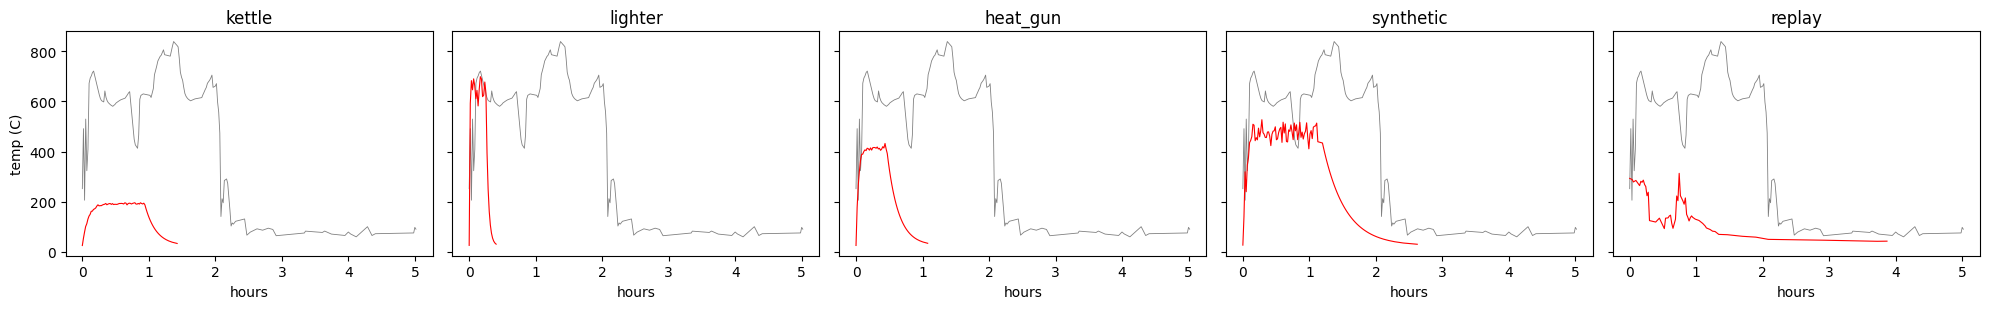

In [15]:
rng = np.random.default_rng(SEED)
ref = segments[0]
fig, axes = plt.subplots(1, len(ATTACKS), figsize=(20, 3.2), sharey=True)
for ax, kind in zip(axes, ATTACKS):
    offsets, temp = make_attack(kind, 25.0, rng)
    ax.plot(ref["offsets"] / 3600, ref["temp"], color="gray", lw=0.6)
    ax.plot(offsets / 3600, temp, color="red", lw=0.8)
    ax.set_title(kind)
    ax.set_xlabel("hours")
axes[0].set_ylabel("temp (C)")
plt.tight_layout()
plt.show()

### run the simulation on held-out households and summarize

Compare ambient-temperature and humidity responses during real events and quiet controls.

In [16]:
def response_stats(df, windows):
    """Ambient-temp rise and humidity change inside each (start, end) window,
    relative to the median of the 2 h before it."""
    out = []
    for a, b in windows:
        before = df[(df["ts"] >= a - 7200) & (df["ts"] < a)]
        during = df[(df["ts"] >= a) & (df["ts"] <= b + 1800)]
        if len(before) < 2 or len(during) < 2:
            continue
        out.append({
            "amb_rise": during["amb_temp"].max() - before["amb_temp"].median(),
            "hum_change": during["humidity"].max() - before["humidity"].median(),
        })
    return pd.DataFrame(out)


rng = np.random.default_rng(SEED)
real, ctrl = [], []
for hid in TRAIN_IDS:
    df = dfs[hid]
    events = extract_events(label_cooking(df), df["ts"].to_numpy())
    event_days = usage_days(events)
    real.append(response_stats(df, events))

    # control: random 1 h windows on days with no cooking event
    quiet = df[~pd.Index(df.index.date).isin(list(event_days))]
    starts = rng.choice(quiet["ts"].to_numpy(), size=min(40, len(quiet)), replace=False)
    ctrl.append(response_stats(df, [(s, s + 3600) for s in starts]))

real, ctrl = pd.concat(real), pd.concat(ctrl)
q = [0.1, 0.5, 0.9]
print("real events\n", real.quantile(q).round(2))
print("\nquiet windows\n", ctrl.quantile(q).round(2))

real events
      amb_rise  hum_change
0.1     -1.10      -11.96
0.5      2.91        0.37
0.9     24.03        6.85

quiet windows
      amb_rise  hum_change
0.1      -1.9       -3.26
0.5       4.4        1.66
0.9      12.2        7.13


Store true usage dates once in a household-keyed mapping.

In [17]:
# Keep true usage dates in a household-keyed mapping for evaluation and attack tests.
true_days_by_household = {
    hid: usage_days(extract_events(g["y"].to_numpy(), g["ts"].to_numpy()))
    for hid, g in test.groupby("household")
}

Measure how replay-event row sequences compare with the duplicate library.

In [18]:
rng_d = np.random.default_rng(SEED)
rows = []
for hid in TEST_IDS:
    df = dfs[hid]
    for date in sorted(set(df.index.date) - true_days_by_household[hid]):
        if verify_day(df, hid, date)[0]:          # skip days the model already flags without an attack
            continue
        attacked = inject(df, "replay", date, rng_d)
        if attacked is None:
            continue
        pred = (final_model.predict_proba(build_features(attacked)[FEATURES])[:, 1] >= THRESH).astype(int)
        ts, temp = attacked["ts"].to_numpy(), attacked["temp"].to_numpy()
        for a, b in extract_events(pred, ts):
            if local_dt(a).date() != date:
                continue
            n = n_rows(ts, a, b)
            if n < MIN_FP_ROWS:                   # too short to compare, auto-verified
                rows.append({"event_rows": n, "best_similarity": np.nan})
                continue
            seq = row_seq(ts, temp, a, b)
            sims = [best_match(seq, r["seq"]) for r in library if r["key"] != (hid, date)]
            rows.append({"event_rows": n, "best_similarity": max(sims) if sims else np.nan})

diag = pd.DataFrame(rows)
print(f"duplicate threshold: {DUP_THRESH:.3f} | library size: {len(library)}")
print(f"events under {MIN_FP_ROWS} rows (auto-verified): {(diag['event_rows'] < MIN_FP_ROWS).mean():.0%}")
print(diag.loc[diag["event_rows"] >= MIN_FP_ROWS, "best_similarity"].describe().round(3))

duplicate threshold: 0.980 | library size: 132
events under 10 rows (auto-verified): 22%
count    35.000
mean      0.935
std       0.070
min       0.731
25%       0.902
50%       0.957
75%       0.995
max       1.000
Name: best_similarity, dtype: float64


Explain global LightGBM feature contributions with a SHAP summary plot.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


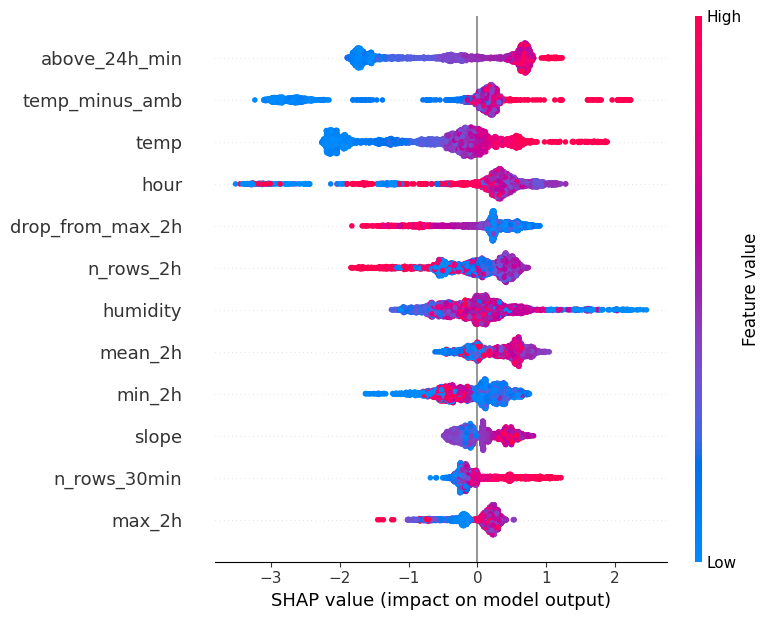

above_24h_min       0.912
temp_minus_amb      0.808
temp                0.784
hour                0.584
drop_from_max_2h    0.431
n_rows_2h           0.406
humidity            0.406
mean_2h             0.382
min_2h              0.343
slope               0.276
dtype: float64


In [19]:
import shap

sample = test[FEATURES]
sv = shap.TreeExplainer(final_model).shap_values(sample)
if isinstance(sv, list):                     # older shap versions return one array per class
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, sample, max_display=12)
imp = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
print(imp.head(10).round(3))

Build daily predicted-event counts for train and held-out households.

In [20]:
from collections import Counter

allp = pd.concat([train, test])              # train["pred"] is out-of-fold, test["pred"] is held-out
rows = []
for hid, g in allp.groupby("household"):
    cnt = Counter(local_dt(a).date() for a, _ in extract_events(g["pred"].to_numpy(), g["ts"].to_numpy()))
    for d in pd.date_range(g.index.min().normalize(), g.index.max().normalize()).date:
        rows.append({"household": hid, "date": d, "n_events": cnt.get(d, 0)})
daily = pd.DataFrame(rows).sort_values(["household", "date"])

Create rolling usage features and a future inactivity target.

In [21]:
H = 3

def add_feats(g):
    g = g.copy()
    n = g["n_events"]
    g["use_1d"] = n
    g["use_3d"] = n.rolling(3, min_periods=1).sum()
    g["use_7d"] = n.rolling(7, min_periods=1).sum()
    last = g["date"].where(n > 0).ffill()    # date of the most recent usage
    g["days_since_use"] = [(d - l).days if pd.notna(l) else 99 for d, l in zip(g["date"], last)]
    future = sum(n.shift(-k) for k in range(1, H + 1))     # events in the next H days
    g["abandon"] = (future == 0).astype(float).where(future.notna())
    return g

daily = pd.concat([add_feats(g) for _, g in daily.groupby("household")])
data = daily.dropna(subset=["abandon"])

Evaluate the abandonment-risk model with leave-one-household-out validation.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

AF = ["use_1d", "use_3d", "use_7d", "days_since_use"]
y = data["abandon"]
risk = np.zeros(len(data))
for fit, val in LeaveOneGroupOut().split(data[AF], y, data["household"]):
    m = LogisticRegression(class_weight="balanced", max_iter=1000).fit(data[AF].iloc[fit], y.iloc[fit])
    risk[val] = m.predict_proba(data[AF].iloc[val])[:, 1]

print(f"rows {len(data)} | base rate {y.mean():.2f} | ROC-AUC {roc_auc_score(y, risk):.3f} | PR-AUC {average_precision_score(y, risk):.3f}")
print(f"naive baseline (days_since_use alone) ROC-AUC {roc_auc_score(y, data['days_since_use']):.3f}")

rows 78 | base rate 0.29 | ROC-AUC 0.715 | PR-AUC 0.487
naive baseline (days_since_use alone) ROC-AUC 0.813


Fit the final abandonment model and estimate the latest risk by household.

In [23]:
final_ab = LogisticRegression(class_weight="balanced", max_iter=1000).fit(data[AF], y)
latest = daily.groupby("household").tail(1).copy()
latest["abandon_risk"] = final_ab.predict_proba(latest[AF])[:, 1]
print(latest[["household", "date", "days_since_use", "abandon_risk"]].round(2).to_string(index=False))

household       date  days_since_use  abandon_risk
   SUM_11 2019-10-17               2          0.71
   SUM_17 2019-10-17               0          0.00
   SUM_18 2019-10-17               0          0.26
   SUM_21 2019-10-17              13          0.68
    SUM_7 2019-10-17               3          0.94
    SUM_9 2019-10-17               1          0.65


Compare the inactivity rule with the abandonment target.

In [24]:
from sklearn.metrics import precision_score, recall_score

rule = (data["days_since_use"] >= H).astype(int)
print(f"rule days_since_use >= {H}: precision {precision_score(y, rule):.2f} | recall {recall_score(y, rule):.2f} | rows {len(data)}")

latest["abandon_flag"] = latest["days_since_use"] >= H
print(latest[["household", "days_since_use", "abandon_flag"]].to_string(index=False))

rule days_since_use >= 3: precision 0.70 | recall 0.61 | rows 78
household  days_since_use  abandon_flag
   SUM_11               2         False
   SUM_17               0         False
   SUM_18               0         False
   SUM_21              13          True
    SUM_7               3          True
    SUM_9               1         False


Plot SHAP waterfall explanations for representative cooking and quiet rows.

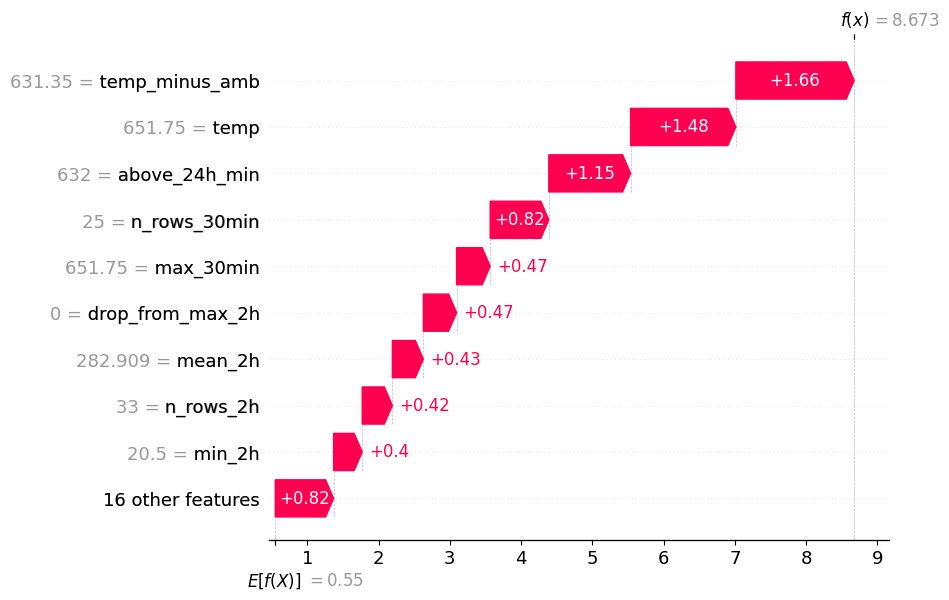

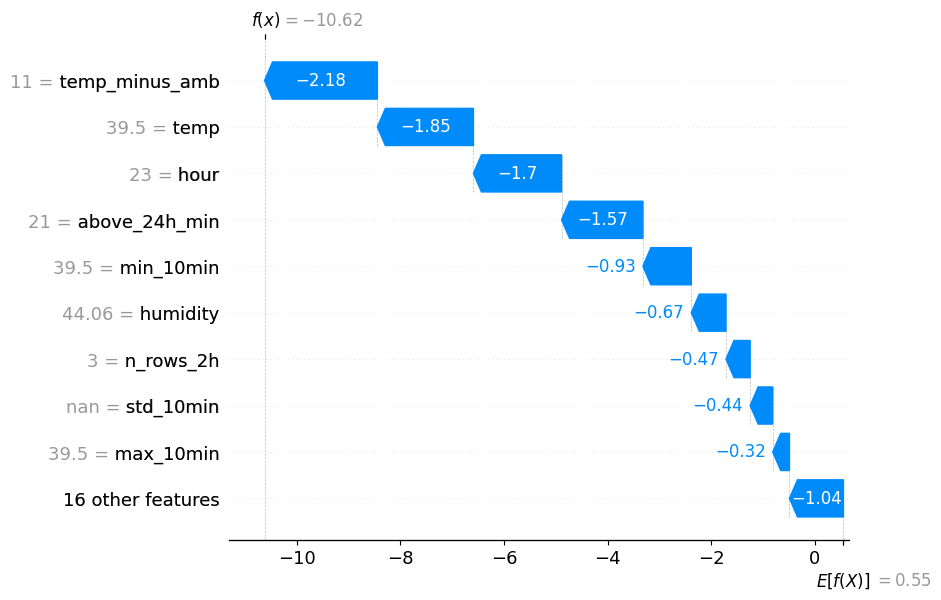

In [25]:
explainer = shap.TreeExplainer(final_model)
exp = explainer(test[FEATURES])
if exp.values.ndim == 3:                     # newer shap returns one slice per class
    exp = exp[:, :, 1]

i_cook = int(np.argmax(np.where(test["y"] == 1, test["prob"], -1)))    # most confident real cooking row
i_quiet = int(np.argmin(np.where(test["y"] == 0, test["prob"], 2)))    # most confident quiet row

shap.plots.waterfall(exp[i_cook], max_display=10)
shap.plots.waterfall(exp[i_quiet], max_display=10)

Calibrate the plausibility gate from rule-labeled training events using the 0.05 quantile.

In [26]:
def event_stats(ts, temp, a, b):
    """Summarize peak temperature, event duration, and row-to-row temperature variation."""
    t = temp[(ts >= a) & (ts <= b)]
    d = np.diff(t)
    return {"peak": t.max(), "dur_min": (b - a) / 60, "flicker": d.std() if len(d) > 2 else np.nan}

# Calibrate the plausibility floor from rule-labeled real training events, not model predictions.
train_stats = pd.DataFrame([
    event_stats(g["ts"].to_numpy(), g["temp"].to_numpy(), a, b)
    for _, g in train.groupby("household")
    for a, b in extract_events(g["y"].to_numpy(), g["ts"].to_numpy())
])
LB = train_stats.quantile(0.05).to_dict()
print({k: round(v, 1) for k, v in LB.items()}, "| train events:", len(train_stats))

def plausible(st):
    ok = st["peak"] >= LB["peak"] and st["dur_min"] >= LB["dur_min"]
    if not np.isnan(st["flicker"]):
        ok = ok and st["flicker"] >= LB["flicker"]
    return bool(ok)

{'peak': 305.0, 'dur_min': 12.9, 'flicker': 0.3} | train events: 115


Apply the plausibility gate before accepting a predicted event for a verified day.

In [27]:
def verify_day_gated(df, hid, date):
    X = build_features(df)
    pred = (final_model.predict_proba(X[FEATURES])[:, 1] >= THRESH).astype(int)
    ts, temp = df["ts"].to_numpy(), df["temp"].to_numpy()
    for a, b in extract_events(pred, ts):
        if local_dt(a).date() != date or not plausible(event_stats(ts, temp, a, b)):
            continue
        too_short = n_rows(ts, a, b) < MIN_FP_ROWS
        if too_short or not is_duplicate(row_seq(ts, temp, a, b), (hid, date)):
            return True
    return False

Test five sensor attacks against gated verification and measure real-day retention.

In [28]:
rng_e = np.random.default_rng(SEED)
res = {k: [0, 0] for k in ATTACKS}               # [verified = missed, tried]
for hid in TEST_IDS:
    df = dfs[hid]
    empty = [d for d in sorted(set(df.index.date) - true_days_by_household[hid]) if not verify_day_gated(df, hid, d)]
    for kind in ATTACKS:
        for d in empty:
            for _ in range(N_REPS):
                att = inject(df, kind, d, rng_e)
                if att is None:
                    continue
                res[kind][0] += verify_day_gated(att, hid, d)
                res[kind][1] += 1

attack_miss_rates = {k: round(v[0] / max(v[1], 1), 3) for k, v in res.items()}
print("miss rate:", attack_miss_rates)
print("attacks tried:", {k: v[1] for k, v in res.items()})
real_ok = sum(verify_day_gated(dfs[h], h, d) for h in TEST_IDS for d in true_days_by_household[h])
real_days_total = sum(len(true_days_by_household[h]) for h in TEST_IDS)
print(f"real days still verified: {real_ok} of {real_days_total}")

miss rate: {'kettle': 0.0, 'lighter': 0.8, 'heat_gun': 0.8, 'synthetic': 1.0, 'replay': 0.583}
attacks tried: {'kettle': 60, 'lighter': 60, 'heat_gun': 60, 'synthetic': 60, 'replay': 60}
real days still verified: 10 of 10


Export gated event proofs, flag exact copies, and retain one record per stove-day.

In [29]:
import hashlib, json

def event_hash(ts, temp, a, b):
    """Hash the quantized thermocouple trace for an event."""
    m = (ts >= a) & (ts <= b)
    return hashlib.sha256(np.round(temp[m] * 4).astype(np.int64).tobytes()).hexdigest()

exports, seen = [], {}
gate_removed = 0
for hid, g in test.groupby("household"):
    ts, temp = g["ts"].to_numpy(), g["temp"].to_numpy()
    data_hash = hashlib.sha256((ROOT / f"{hid}.csv").read_bytes()).hexdigest()
    for a, b in extract_events(g["pred"].to_numpy(), ts):
        # Reject implausible events before computing or recording any proof hashes.
        if not plausible(event_stats(ts, temp, a, b)):
            gate_removed += 1
            continue
        day, h = str(local_dt(a).date()), event_hash(ts, temp, a, b)
        seen.setdefault(h, set()).add((hid, day))
        exports.append({"stove_id": hid, "date": day, "event_hash": h, "data_hash": data_hash})

for e in exports:
    e["exact_copy"] = len(seen[e["event_hash"]]) > 1

first = {}
for e in exports:
    if not e["exact_copy"]:
        first.setdefault((e["stove_id"], e["date"]), e)
verified_export = list(first.values())
with open("/kaggle/working/verified_days.json", "w") as f:
    json.dump(verified_export, f, indent=2)
exported_stove_days = len(verified_export)
print("events after gate:", len(exports), "| exact copies:", sum(e["exact_copy"] for e in exports))
print("stove-days exported:", exported_stove_days, "| events removed by plausibility gate:", gate_removed)

events after gate: 29 | exact copies: 0
stove-days exported: 12 | events removed by plausibility gate: 9


Check that exact hashes catch an unchanged trace while noisy replay changes the exact hash.

In [30]:
g = test[test["household"] == "SUM_18"]
ts, temp = g["ts"].to_numpy(), g["temp"].to_numpy()
a, b = extract_events(g["pred"].to_numpy(), ts)[0]

original = event_hash(ts, temp, a, b)
shifted_ts = ts + 86400                                  # same trace, one day later
copy = event_hash(shifted_ts, temp, a + 86400, b + 86400)
print("exact copy on another day caught:", original == copy)

noisy = temp + np.random.default_rng(SEED).normal(0, 2.0, len(temp))   # noisy replay
print("noisy replay caught by hash:", original == event_hash(ts, noisy, a, b), "(expected False, fuzzy check handles it)")

exact copy on another day caught: True
noisy replay caught by hash: False (expected False, fuzzy check handles it)


Install the Python Ethereum testing and Solidity compilation dependencies.

In [31]:
pip install -q web3 eth-tester py-evm py-solc-x

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 798.6/798.6 kB 19.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.8/176.8 kB 4.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 586.3/586.3 kB 16.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.5/102.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.8/47.8 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 kB 10.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━

Write the unchanged ProofOfUse.sol contract to the Kaggle working directory.

In [32]:
%%writefile /kaggle/working/ProofOfUse.sol
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.20;

contract ProofOfUse {
    uint256 public constant PAY_PER_DAY = 0.001 ether;
    uint256 public constant MIN_STAKE = 0.01 ether;
    uint256 public constant MAX_EVENTS_PER_DAY = 2;
    uint256 public constant HOLDBACK = 3 days;
    uint256 public constant SLASH = 0.005 ether;

    address public immutable oracle;
    address public immutable auditor;
    uint256 public pool;

    struct Stove {
        address operator;
        address sensor;            // key held by the stove's sensor; signs each day's raw data hash
        address[] households;
        bytes32 baseline;
        bytes32 head;
        uint256 stake;
    }
    struct Claim { bytes32 stoveId; uint64 releaseAt; bool done; }
    struct Day { bytes32 id; uint32 day; bytes32 rawHash; bytes32 prevHead; }

    mapping(bytes32 => Stove) public stoves;
    mapping(bytes32 => bool) public issued;
    mapping(bytes32 => bool) public usedEvent;
    mapping(address => uint256) public balance;
    Claim[] public claims;

    event DayIssued(bytes32 indexed stoveId, uint32 day, uint256 claimId);
    event Slashed(uint256 indexed claimId, uint256 amount);

    constructor(address _oracle, address _auditor) { oracle = _oracle; auditor = _auditor; }

    function fund() external payable { pool += msg.value; }

    function registerStove(bytes32 id, address[] calldata households, bytes32 baseline, address sensor) external payable {
        require(stoves[id].operator == address(0), "exists");
        require(msg.value >= MIN_STAKE && households.length > 0 && sensor != address(0), "stake/households/sensor");
        Stove storage s = stoves[id];
        s.operator = msg.sender;
        s.sensor = sensor;
        s.households = households;
        s.baseline = baseline;
        s.head = baseline;
        s.stake = msg.value;
    }

    function submitDay(Day calldata d, bytes32[] calldata eventHashes, bytes calldata sig) external {
        require(msg.sender == oracle, "oracle only");
        Stove storage s = stoves[d.id];
        require(s.operator != address(0), "no stove");
        require(eventHashes.length > 0 && eventHashes.length <= MAX_EVENTS_PER_DAY, "event cap");
        require(d.prevHead == s.head, "chain broken");
        // the sensor signed (stove, day, raw data hash, previous head): edited data or a forged signer fails here
        bytes32 digest = keccak256(abi.encode(d.id, d.day, d.rawHash, d.prevHead));
        require(_signer(digest, sig) == s.sensor, "bad sensor signature");
        bytes32 key = keccak256(abi.encode(d.id, d.day));
        require(!issued[key], "day already issued");
        issued[key] = true;
        for (uint256 i; i < eventHashes.length; i++) {
            require(!usedEvent[eventHashes[i]], "duplicate event");
            usedEvent[eventHashes[i]] = true;
        }
        s.head = keccak256(abi.encodePacked(d.prevHead, d.rawHash));   // contract computes the new head
        claims.push(Claim(d.id, uint64(block.timestamp + HOLDBACK), false));
        emit DayIssued(d.id, d.day, claims.length - 1);
    }

    function _signer(bytes32 digest, bytes calldata sig) internal pure returns (address) {
        require(sig.length == 65, "bad sig length");
        bytes32 r = bytes32(sig[0:32]);
        bytes32 sv = bytes32(sig[32:64]);
        uint8 v = uint8(sig[64]);
        require(v == 27 || v == 28, "bad v");
        require(uint256(sv) <= 0x7FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF5D576E7357A4501DDFE92F46681B20A0, "bad s");
        bytes32 ethDigest = keccak256(abi.encodePacked("\x19Ethereum Signed Message:\n32", digest));
        address a = ecrecover(ethDigest, v, r, sv);
        require(a != address(0), "bad signature");
        return a;
    }

    function challenge(uint256 claimId) external {
        require(msg.sender == auditor, "auditor only");
        Claim storage c = claims[claimId];
        require(!c.done && block.timestamp < c.releaseAt, "closed");
        c.done = true;
        Stove storage s = stoves[c.stoveId];
        uint256 cut = s.stake < SLASH ? s.stake : SLASH;
        s.stake -= cut;
        pool += cut;
        emit Slashed(claimId, cut);
    }

    function release(uint256 claimId) external {
        Claim storage c = claims[claimId];
        require(!c.done && block.timestamp >= c.releaseAt, "not releasable");
        require(pool >= PAY_PER_DAY, "pool empty");
        c.done = true;
        pool -= PAY_PER_DAY;
        Stove storage s = stoves[c.stoveId];
        uint256 share = PAY_PER_DAY / s.households.length;
        for (uint256 i; i < s.households.length; i++) balance[s.households[i]] += share;
    }

    function withdraw() external {
        uint256 amt = balance[msg.sender];
        balance[msg.sender] = 0;
        (bool ok, ) = msg.sender.call{value: amt}("");
        require(ok, "send failed");
    }
}

Writing /kaggle/working/ProofOfUse.sol


Compile ProofOfUse.sol and deploy it to an in-memory Ethereum test chain.

In [33]:
import json, datetime as dt
from web3 import Web3, EthereumTesterProvider
from solcx import install_solc, compile_files
from eth_utils import keccak

install_solc("0.8.20")
out = compile_files(["/kaggle/working/ProofOfUse.sol"], solc_version="0.8.20", output_values=["abi", "bin"])
iface = next(iter(out.values()))

w3 = Web3(EthereumTesterProvider())
oracle, auditor, operator, *hh = w3.eth.accounts       # test accounts, one household per stove
factory = w3.eth.contract(abi=iface["abi"], bytecode=iface["bin"])
rcpt = w3.eth.wait_for_transaction_receipt(factory.constructor(oracle, auditor).transact({"from": oracle}))
c = w3.eth.contract(address=rcpt.contractAddress, abi=iface["abi"])

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Load the exported JSON, register stoves, and submit each verified day on-chain.

In [34]:
from eth_account import Account
from eth_account.messages import encode_defunct
from eth_abi import encode as abi_encode     # on older eth_abi, use encode_abi

records = json.load(open("/kaggle/working/verified_days.json"))
b32 = bytes.fromhex
stoves = sorted({r["stove_id"] for r in records})
sid = {s: keccak(text=s) for s in stoves}
sensor_key = {s: Account.create() for s in stoves}      # simulated: one key per stove

# What the sensor would hash: that local day's raw timestamps and thermocouple readings
raw_by_day = {}
for (hid, d), g in test.groupby(["household", test.index.date]):
    raw_by_day[(hid, str(d))] = hashlib.sha256(
        g["ts"].to_numpy().astype(np.int64).tobytes()
        + np.round(g["temp"].to_numpy() * 4).astype(np.int64).tobytes()).digest()

head = {}
c.functions.fund().transact({"from": operator, "value": w3.to_wei(1, "ether")})
for i, s in enumerate(stoves):
    baseline = b32(next(r["data_hash"] for r in records if r["stove_id"] == s))
    c.functions.registerStove(sid[s], [hh[i]], baseline, sensor_key[s].address).transact(
        {"from": operator, "value": w3.to_wei(0.01, "ether")})
    head[s] = baseline

def day_num(d):
    return (dt.date.fromisoformat(d) - dt.date(1970, 1, 1)).days

def sign_day(s, day, raw, prev, key=None):
    digest = keccak(abi_encode(["bytes32", "uint32", "bytes32", "bytes32"], [sid[s], day, raw, prev]))
    return Account.sign_message(encode_defunct(digest), (key or sensor_key[s]).key).signature

def submit(s, day, hashes, raw, prev, sig=None):
    sig = sig or sign_day(s, day, raw, prev)
    c.functions.submitDay((sid[s], day, raw, prev), hashes, sig).transact({"from": oracle})
    return keccak(prev + raw)        # same rule the contract uses for the new head

for r in records:
    s = r["stove_id"]
    head[s] = submit(s, day_num(r["date"]), [b32(r["event_hash"])], raw_by_day[(s, r["date"])], head[s])
print(len(records), "stove-days issued on-chain, each signed by its sensor key")

/tmp/ipykernel_57/1169992703.py:5: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/verified_days.json' mode='r' encoding='utf-8'>
  records = json.load(open("/kaggle/working/verified_days.json"))
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


12 stove-days issued on-chain, each signed by its sensor key


Verify the contract blocks duplicate-day, replay, stale-head, and event-cap attacks.

In [35]:
blocked_attacks = 0
def must_fail(label, fn, expected):
    global blocked_attacks
    try:
        fn()
        print(f"{label}: NOT BLOCKED")
    except Exception as e:
        ok = expected in str(e)
        blocked_attacks += ok
        print(f"{label}: {'blocked' if ok else 'FAILED FOR ANOTHER REASON'} | {str(e)[:90]}")

r0 = records[0]; s0 = r0["stove_id"]; d0 = day_num(r0["date"]); old = b32(r0["data_hash"])
fresh = lambda n: keccak(text=f"fake{n}")
raw0 = raw_by_day[(s0, r0["date"])]

must_fail("same day twice", lambda: submit(s0, d0, [fresh(1)], fresh("r1"), head[s0]), "day already issued")
must_fail("replayed event on a new day", lambda: submit(s0, d0 + 100, [b32(r0["event_hash"])], fresh("r2"), head[s0]), "duplicate event")
must_fail("backfill with stale chain head", lambda: submit(s0, d0 + 101, [fresh(2)], fresh("r3"), old), "chain broken")
must_fail("3 events in one day", lambda: submit(s0, d0 + 102, [fresh(3), fresh(4), fresh(5)], fresh("r4"), head[s0]), "event cap")
# new: the oracle signs with its own key instead of the sensor's
must_fail("forged signer", lambda: submit(s0, d0 + 103, [fresh(6)], fresh("r5"), head[s0],
          sign_day(s0, d0 + 103, fresh("r5"), head[s0], key=Account.create())), "bad sensor signature")
# new: data edited after the sensor signed it
signed = sign_day(s0, d0 + 104, fresh("r6"), head[s0])
must_fail("data edited after signing", lambda: submit(s0, d0 + 104, [fresh(7)], fresh("r6-edited"), head[s0], signed), "bad sensor signature")

assert blocked_attacks == 6, f"Expected 6 blocked; got {blocked_attacks}"
print(f"Contract attack checks blocked: {blocked_attacks}/6")

same day twice: blocked | execution reverted: day already issued
replayed event on a new day: blocked | execution reverted: duplicate event
backfill with stale chain head: blocked | execution reverted: chain broken
3 events in one day: blocked | execution reverted: event cap
forged signer: blocked | execution reverted: bad sensor signature
data edited after signing: blocked | execution reverted: bad sensor signature
Contract attack checks blocked: 6/6


Advance past the holdback period, release all claims, and calculate household payouts.

In [36]:
tester = w3.provider.ethereum_tester
tester.time_travel(w3.eth.get_block("latest")["timestamp"] + 4 * 86400)
tester.mine_blocks(1)
for i in range(len(records)):
    c.functions.release(i).transact({"from": operator})
payouts = {s: float(w3.from_wei(c.functions.balance(hh[i]).call(), "ether")) for i, s in enumerate(stoves)}
print(payouts)

{'SUM_18': 0.009, 'SUM_21': 0.003}


Summarize model, usage, gate, attack, on-chain, and payout results from computed variables.

In [37]:
print("Results summary")
print(f"Train OOF PR-AUC: {OOF_PR_AUC:.3f} | threshold: {THRESH:.3f}")

for hid in TRAIN_IDS:
    mask = (groups == hid).to_numpy()
    print(f"{hid} train OOF PR-AUC: {average_precision_score(y_tr[mask], oof[mask]):.3f} | "
          f"F1: {f1_score(y_tr[mask], oof[mask] >= THRESH):.3f}")

for hid, g in test.groupby("household"):
    print(f"{hid} held-out PR-AUC: {average_precision_score(g['y'], g['prob']):.3f} | "
          f"F1: {f1_score(g['y'], g['pred']):.3f}")

print(f"Usage days (true / predicted / caught): {true_usage_days} / {predicted_usage_days} / {caught_usage_days}")
print("Attack miss rates with gate:", attack_miss_rates)
print(f"Real days still verified: {real_ok} / {real_days_total}")
print(f"Stove-days before / after gate: {pre_gate_stove_days} / {exported_stove_days}")
print(f"Stove-days issued on-chain: {len(records)}")
print(f"Contract attacks blocked: {blocked_attacks}/6")
print("Payouts per household:", payouts)

Results summary
Train OOF PR-AUC: 0.934 | threshold: 0.237
SUM_7 train OOF PR-AUC: 0.950 | F1: 0.858
SUM_9 train OOF PR-AUC: 0.944 | F1: 0.856
SUM_11 train OOF PR-AUC: 0.765 | F1: 0.714
SUM_17 train OOF PR-AUC: 0.945 | F1: 0.867
SUM_18 held-out PR-AUC: 0.885 | F1: 0.878
SUM_21 held-out PR-AUC: 0.919 | F1: 0.844
Usage days (true / predicted / caught): 10 / 12 / 10
Attack miss rates with gate: {'kettle': 0.0, 'lighter': 0.8, 'heat_gun': 0.8, 'synthetic': 1.0, 'replay': 0.583}
Real days still verified: 10 / 10
Stove-days before / after gate: 12 / 12
Stove-days issued on-chain: 12
Contract attacks blocked: 6/6
Payouts per household: {'SUM_18': 0.009, 'SUM_21': 0.003}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:
# Rows after cleaning (what the model actually used)
for name, ids in [("train", TRAIN_IDS), ("test", TEST_IDS)]:
    n = {hid: len(dfs[hid]) for hid in ids}
    print(name, n, "| total:", sum(n.values()))
print("all 6 households:", sum(len(dfs[h]) for h in TRAIN_IDS + TEST_IDS))

train {'SUM_7': 2731, 'SUM_9': 687, 'SUM_11': 1024, 'SUM_17': 5369} | total: 9811
test {'SUM_18': 1977, 'SUM_21': 753} | total: 2730
all 6 households: 12541


In [39]:
import json, os

APP = "/kaggle/working/app_data"
os.makedirs(APP, exist_ok=True)
naive_local = lambda sec: local_dt(sec).tz_localize(None)    # local wall-clock time, no timezone

# 1. Sensor traces of the held-out households with the model output
tr = test[["household", "temp", "prob", "pred"]].copy()
tr[["temp", "prob"]] = tr[["temp", "prob"]].round(3)
tr["time"] = tr.index.tz_localize(None)
tr[["time", "household", "temp", "prob", "pred"]].to_csv(f"{APP}/traces.csv", index=False)

# 2. One row per predicted event with its plausibility and exact-copy status
ev_rows = []
for hid, g in test.groupby("household"):
    ts, temp = g["ts"].to_numpy(), g["temp"].to_numpy()
    for a, b in extract_events(g["pred"].to_numpy(), ts):
        st_ = event_stats(ts, temp, a, b)
        h = event_hash(ts, temp, a, b)
        ev_rows.append({
            "household": hid, "date": str(local_dt(a).date()),
            "start": naive_local(a), "end": naive_local(b),
            "peak": round(float(st_["peak"]), 1), "dur_min": round(float(st_["dur_min"]), 1),
            "flicker": None if np.isnan(st_["flicker"]) else round(float(st_["flicker"]), 2),
            "plausible": bool(plausible(st_)),
            "exact_copy": len(seen.get(h, ())) > 1,
            "event_hash": h,
        })
events_df = pd.DataFrame(ev_rows)
events_df.to_csv(f"{APP}/events.csv", index=False)

# 3. One row per stove-day with its final status
exported = {(r["stove_id"], r["date"]) for r in verified_export}
day_rows = []
for hid, g in test.groupby("household"):
    for d in pd.date_range(g.index.min().normalize(), g.index.max().normalize()).date:
        ev = events_df[(events_df["household"] == hid) & (events_df["date"] == str(d))]
        if (hid, str(d)) in exported:
            status = "Verified"
        elif ev.empty:
            status = "No cooking detected"
        elif not ev["plausible"].any():
            status = "Rejected: failed plausibility check"
        else:
            status = "Rejected: exact copy"
        day_rows.append({"household": hid, "date": str(d), "status": status,
                         "events": len(ev), "rule_cooking": d in true_days_by_household[hid]})
pd.DataFrame(day_rows).to_csv(f"{APP}/days.csv", index=False)

# 4. On-chain records with the hash links, rebuilt exactly as the contract computes them
chain_rows, prev = [], {}
for r in records:
    s = r["stove_id"]
    p = prev.get(s) or b32(next(x["data_hash"] for x in records if x["stove_id"] == s))
    raw = raw_by_day[(s, r["date"])]
    new = keccak(p + raw)                 # same rule as the contract: keccak(prevHead, rawHash)
    prev[s] = new
    chain_rows.append({"claim_id": len(chain_rows), "stove_id": s, "date": r["date"],
                       "event_hash": r["event_hash"], "raw_hash": raw.hex(),
                       "prev_head": p.hex(), "new_head": new.hex()})
pd.DataFrame(chain_rows).to_csv(f"{APP}/chain.csv", index=False)

# 5. Contract attacks re-run to capture the revert reason of each (failed calls change nothing)
forged = lambda day, raw: sign_day(s0, day, raw, head[s0], key=Account.create())   # not the stove's sensor key
signed_once = sign_day(s0, d0 + 104, fresh("r6"), head[s0])                        # signature over the original data

CASES = [
    ("Claim the same day twice", "Submit a second credit for a day that was already issued.",
     "day already issued", lambda: submit(s0, d0, [fresh(1)], fresh("r1"), head[s0])),
    ("Replay an old event", "Reuse a real cooking trace to claim a new day.",
     "duplicate event", lambda: submit(s0, d0 + 100, [b32(r0["event_hash"])], fresh("r2"), head[s0])),
    ("Backfill with an old record", "Insert a day using an outdated data link.",
     "chain broken", lambda: submit(s0, d0 + 101, [fresh(2)], fresh("r3"), old)),
    ("Claim 3 events in one day", "Submit more cooking events than the daily limit.",
     "event cap", lambda: submit(s0, d0 + 102, [fresh(3), fresh(4), fresh(5)], fresh("r4"), head[s0])),
    ("Forged signer", "Sign the day with a key that is not the stove's sensor.",
     "bad sensor signature", lambda: submit(s0, d0 + 103, [fresh(6)], fresh("r5"), head[s0], forged(d0 + 103, fresh("r5")))),
    ("Data edited after signing", "Change the readings after the sensor signed them.",
     "bad sensor signature", lambda: submit(s0, d0 + 104, [fresh(7)], fresh("r6-edited"), head[s0], signed_once)),
]

contract = []
for name, what, expected, fn in CASES:
    try:
        fn()
        contract.append({"attack": name, "what": what, "blocked": False, "reason": "not blocked"})
    except Exception as e:
        ok = expected in str(e)
        contract.append({"attack": name, "what": what, "blocked": ok, "reason": expected if ok else str(e)[:120]})
assert all(c_["blocked"] for c_ in contract), contract

sensor = [{"attack": k, "tried": int(v[1]), "got_through": int(v[0])} for k, v in res.items()]
json.dump({"contract": contract, "sensor": sensor}, open(f"{APP}/attacks.json", "w"), indent=2)

# 6. Headline numbers
summary = {
    "rows_total": int(sum(len(dfs[h]) for h in TRAIN_IDS + TEST_IDS)),
    "rows_test": int(sum(len(dfs[h]) for h in TEST_IDS)),
    "train_ids": TRAIN_IDS, "test_ids": TEST_IDS,
    "oof_pr_auc": round(float(OOF_PR_AUC), 3), "threshold": round(float(THRESH), 3),
    "heldout": {hid: {"pr_auc": round(float(average_precision_score(g["y"], g["prob"])), 3),
                      "f1": round(float(f1_score(g["y"], g["pred"])), 3)}
                for hid, g in test.groupby("household")},
    "usage_days": {"true": int(true_usage_days), "predicted": int(predicted_usage_days), "caught": int(caught_usage_days)},
    "real_days_verified": [int(real_ok), int(real_days_total)],
    "stove_days_before_gate": int(pre_gate_stove_days), "stove_days_after_gate": int(exported_stove_days),
    "gate": {k: round(float(v), 2) for k, v in LB.items()},
    "payouts": {k: round(float(v), 4) for k, v in payouts.items()},
    "holdback_days": 3, "max_events_per_day": 2,
}
json.dump(summary, open(f"{APP}/summary.json", "w"), indent=2)
print(sorted(os.listdir(APP)))

['attacks.json', 'chain.csv', 'days.csv', 'events.csv', 'summary.json', 'traces.csv']


/tmp/ipykernel_57/3547863653.py:93: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/app_data/attacks.json' mode='w' encoding='utf-8'>
  json.dump({"contract": contract, "sensor": sensor}, open(f"{APP}/attacks.json", "w"), indent=2)
/tmp/ipykernel_57/3547863653.py:111: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/app_data/summary.json' mode='w' encoding='utf-8'>
  json.dump(summary, open(f"{APP}/summary.json", "w"), indent=2)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
# SMEC V4.0 (GS4GG PAA M400-07), Option B: default Minimum Service Level baseline
# Sources are listed in the README "Climate impact: sources". Tags [S1]-[S4] match it.
P_MSL_CAPITA = 0.50    # t wood / person / yr, default Minimum Service Level   [S1] §7.3.6.1 (Option B), SMEC 12
MSL_DISCOUNT = 0.95    # mandatory 5% conservativeness cut                       [S1] §7.4.1.1(b), Eq. 3
NCV          = 0.0156  # TJ / t wood                                             [S1] SMEC 10
EF_CO2       = 112     # tCO2 / TJ, wood                                         [S1] SMEC 8
EF_NONCO2    = 9.46    # tCO2e / TJ, wood (CH4 + N2O, AR5 GWP)                   [S1] SMEC 9
FNRB         = 0.33    # Rwanda national default                                 [S2] Table 3
FNRB_UNC     = 0.30    # uncertainty as a fraction of the value (95% CI)         [S2] para 15
HH_SIZE      = 4       # persons per household (2022 census average)             [S3]
# Equation: baseline = HH_SIZE * P_MSL * 0.95 / 365 * NCV * (EF_CO2 * fNRB + EF_NONCO2)   [S1] Eq. 1 / Eq. 4, usage rate U = 1

def baseline_kg_per_hh_day(fnrb, hh=HH_SIZE):
    """SMEC Eq. 1 for one household-day, with usage rate U = 1 for a verified day."""
    t_wood = hh * P_MSL_CAPITA * MSL_DISCOUNT / 365
    return t_wood * NCV * (EF_CO2 * fnrb + EF_NONCO2) * 1000

# Logged stove-days: every calendar day in each held-out stove's window (same rule as days.csv)
logged_days = sum(
    len(pd.date_range(g.index.min().normalize(), g.index.max().normalize()))
    for _, g in test.groupby("household")
)
verified = {(r["stove_id"], r["date"]) for r in verified_export}
agreed = verified & {(h, str(d)) for h, ds in true_days_by_household.items() for d in ds}
n_ver, n_agr = len(verified), len(agreed)
assert n_ver <= logged_days

kg    = baseline_kg_per_hh_day(FNRB)
kg_lo = baseline_kg_per_hh_day(FNRB * (1 - FNRB_UNC))
kg_hi = baseline_kg_per_hh_day(FNRB * (1 + FNRB_UNC))

print(f"stove-days: logged {logged_days} | verified {n_ver} | verified and rule-agreed {n_agr}")
print(f"baseline per household-day: {kg:.2f} kg CO2e (fNRB +/-30%: {kg_lo:.2f} to {kg_hi:.2f})")
print(f"baseline covered by verified days: {kg*n_ver:.1f} kg (range {kg_lo*n_ver:.1f} to {kg_hi*n_ver:.1f})")
print(f"baseline covered by rule-agreed days: {kg*n_agr:.1f} kg")
print(f"assumed usage (every logged day): {kg*logged_days:.1f} kg = {logged_days/n_ver - 1:.0%} above verified")

stove-days: logged 32 | verified 12 | verified and rule-agreed 10
baseline per household-day: 3.77 kg CO2e (fNRB +/-30%: 2.87 to 4.67)
baseline covered by verified days: 45.2 kg (range 34.4 to 56.0)
baseline covered by rule-agreed days: 37.7 kg
assumed usage (every logged day): 120.6 kg = 167% above verified


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [41]:
for hid in TEST_IDS:
    df = dfs[hid]
    window = pd.date_range(df.index.min().normalize(), df.index.max().normalize()).date
    rows = pd.Series(df.index.date).value_counts()
    gap_h = (df["ts"].diff() / 3600).groupby(df.index.date).max()   # biggest gap ending on each day
    empty = [d for d in window if d not in rows.index]
    print(hid, "| days in window:", len(window), "| days with no rows:", empty,
          "| days with a gap over 12 h:", list(gap_h[gap_h > 12].index))

SUM_18 | days in window: 16 | days with no rows: [] | days with a gap over 12 h: []
SUM_21 | days in window: 16 | days with no rows: [] | days with a gap over 12 h: []


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
import json, pickle, shutil, joblib

APP = Path("/kaggle/working/app_data")
APP.mkdir(exist_ok=True)

joblib.dump(final_model, APP / "model.joblib")
pickle.dump(library, open(APP / "library.pkl", "wb"))

params = {
    "FEATURES": FEATURES, "THRESH": THRESH, "DUP_THRESH": DUP_THRESH, "LB": LB,
    "LOCAL_TZ": LOCAL_TZ, "MIN_FP_ROWS": MIN_FP_ROWS, "ON_DELTA": ON_DELTA,
    "END_FRAC": END_FRAC, "MIN_PEAK": MIN_PEAK, "MIN_EVENT_SEC": MIN_EVENT_SEC,
    "MERGE_GAP_SEC": MERGE_GAP_SEC, "WINDOWS": WINDOWS, "RENAME": RENAME,
    "FLICKER_STD": FLICKER_STD, "N_FP": N_FP, "MAX_COOLDOWN_S": MAX_COOLDOWN_S,
    "hours_pool": hours_pool.tolist(),
    "sensor_keys": {s: sensor_key[s].key.hex() for s in stoves},   # simulated keys, no real hardware
    "baseline_by_stove": {s: records_by[0] for s, records_by in
                          {s: [r["data_hash"] for r in records if r["stove_id"] == s] for s in stoves}.items()},
}
json.dump(params, open(APP / "params.json", "w"), indent=2)

for hid in TEST_IDS:
    shutil.copy(ROOT / f"{hid}.csv", APP / f"{hid}.csv")
shutil.copy("/kaggle/working/ProofOfUse.sol", APP / "ProofOfUse.sol")
shutil.copy("/kaggle/working/verified_days.json", APP / "verified_days.json")

shutil.make_archive("/kaggle/working/app_data", "zip", APP)
print(sorted(p.name for p in APP.iterdir()))

['ProofOfUse.sol', 'SUM_18.csv', 'SUM_21.csv', 'attacks.json', 'chain.csv', 'days.csv', 'events.csv', 'library.pkl', 'model.joblib', 'params.json', 'summary.json', 'traces.csv', 'verified_days.json']


/tmp/ipykernel_57/4171955081.py:7: ResourceWarning: unclosed file <_io.BufferedWriter name='/kaggle/working/app_data/library.pkl'>
  pickle.dump(library, open(APP / "library.pkl", "wb"))
/tmp/ipykernel_57/4171955081.py:20: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/app_data/params.json' mode='w' encoding='utf-8'>
  json.dump(params, open(APP / "params.json", "w"), indent=2)
